# EDA 07 — Home Credit Default Risk (Kaggle 2018)

Nguồn: Kaggle “Home Credit Default Risk” — khách hàng ít/không có lịch sử tín dụng (unbanked).
Bảng chính `application_train` (307.511 hồ sơ); nhãn gốc `TARGET` (1 = gặp khó khăn thanh toán) → `target`.
Kèm 6 bảng phụ (bureau, bureau_balance, previous_application, POS_CASH_balance, credit_card_balance,
installments_payments) nối qua `SK_ID_CURR` / `SK_ID_PREV`, và `application_test` (không nhãn).
File: `data/interim/home_credit/*.parquet`.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.visualization import eda

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
INTERIM = ROOT / "data" / "interim"

## 1. Nạp dữ liệu

In [2]:
NAME = "home_credit"
HC = INTERIM / "home_credit"
df = pd.read_parquet(HC / "application_train.parquet")
df.shape

(307511, 122)

## 2. Tổng quan

In [3]:
ov = eda.overview(df)
display(ov.to_frame("value"))
display(df.head())

,value
rows,307511.0
features,121.0
numeric_features,105.0
categorical_features,16.0
duplicate_rows,0.0
cells_missing_pct,24.4
features_with_missing,67.0


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,...,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,target
0,100002,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0,1
1,100003,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,100004,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,100006,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,...,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0
4,100007,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0


## 3. Nhãn (target: 1 = xấu / vỡ nợ, 0 = tốt)

{'n': 307511, 'n_bad': 24825, 'n_good': 282686, 'bad_rate_pct': 8.07, 'imbalance_ratio': 11.39}


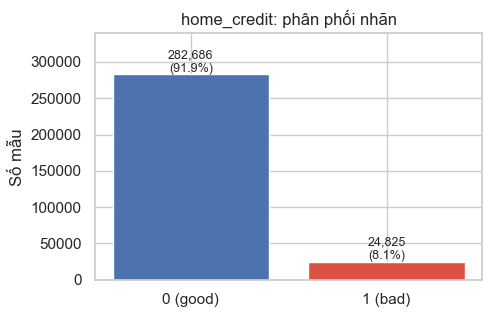

In [4]:
tgt = eda.target_summary(df["target"])
print(tgt)
eda.plot_target(df["target"], NAME)

## 4. Giá trị thiếu

Bảng thứ hai so sánh tỉ lệ nợ xấu khi cột bị thiếu và khi có giá trị: chênh lệch lớn nghĩa là *bản thân việc thiếu* đã mang thông tin về nhãn.

In [5]:
miss = eda.missing_table(df)
display(miss if len(miss) else "Không có giá trị thiếu (NaN).")
mvt = eda.missing_vs_target(df)
display(mvt if len(mvt) else "Không có cột nào đủ lượng thiếu để so sánh bad rate.")

,missing_pct
COMMONAREA_AVG,69.87
COMMONAREA_MODE,69.87
COMMONAREA_MEDI,69.87
NONLIVINGAPARTMENTS_MODE,69.43
NONLIVINGAPARTMENTS_AVG,69.43
NONLIVINGAPARTMENTS_MEDI,69.43
FONDKAPREMONT_MODE,68.39
LIVINGAPARTMENTS_MODE,68.35
LIVINGAPARTMENTS_MEDI,68.35
LIVINGAPARTMENTS_AVG,68.35


,feature,missing_pct,bad_rate_if_missing,bad_rate_if_present,gap
0,DEF_30_CNT_SOCIAL_CIRCLE,0.33,3.53,8.09,-4.56
1,OBS_30_CNT_SOCIAL_CIRCLE,0.33,3.53,8.09,-4.56
2,DEF_60_CNT_SOCIAL_CIRCLE,0.33,3.53,8.09,-4.56
3,OBS_60_CNT_SOCIAL_CIRCLE,0.33,3.53,8.09,-4.56
4,NAME_TYPE_SUITE,0.42,5.42,8.08,-2.66
5,AMT_REQ_CREDIT_BUREAU_YEAR,13.50,10.34,7.72,2.62
6,AMT_REQ_CREDIT_BUREAU_QRT,13.50,10.34,7.72,2.62
7,AMT_REQ_CREDIT_BUREAU_MON,13.50,10.34,7.72,2.62
8,AMT_REQ_CREDIT_BUREAU_WEEK,13.50,10.34,7.72,2.62
9,AMT_REQ_CREDIT_BUREAU_DAY,13.50,10.34,7.72,2.62


## 5. Hồ sơ các biến số

`skew`/`kurtosis`: độ lệch và độ nhọn; `outlier_iqr_pct`: % điểm nằm ngoài 1.5×IQR; `zero_pct`: % giá trị 0; `auc`: AUC đơn biến (max(AUC, 1−AUC)) — thước đo nhanh sức phân biệt của từng biến.

In [6]:
prof = eda.numeric_profile(df)
cols_show = ["n_unique", "min", "median", "max", "skew", "kurtosis", "outlier_iqr_pct", "zero_pct", "auc"]
display(prof.sort_values("auc", ascending=False)[cols_show])
print("Số cột số có |skew| > 2:", int((prof["skew"].abs() > 2).sum()), "/", len(prof))

,n_unique,min,median,max,skew,kurtosis,outlier_iqr_pct,zero_pct,auc
feature,,,,,,,,,
EXT_SOURCE_3,814,0.001,0.535,0.896,-0.409,-0.663,0.000,0.000,0.679
EXT_SOURCE_1,114584,0.015,0.506,0.963,-0.069,-0.965,0.000,0.000,0.666
EXT_SOURCE_2,119831,0.000,0.566,0.855,-0.794,-0.269,0.000,0.000,0.656
DAYS_BIRTH,17460,-25229.000,-15750.000,-7489.000,-0.116,-1.049,0.000,0.000,0.583
OWN_CAR_AGE,62,0.000,9.000,91.000,2.745,9.214,4.716,2.041,0.559
...,...,...,...,...,...,...,...,...,...
SK_ID_CURR,307511,100002.000,278202.000,456255.000,-0.001,-1.199,0.000,0.000,0.502
AMT_REQ_CREDIT_BUREAU_DAY,9,0.000,0.000,9.000,27.043,1151.846,NaN,99.440,0.501
AMT_ANNUITY,13672,1615.500,24903.000,258025.500,1.580,7.707,2.440,0.000,0.500


Số cột số có |skew| > 2: 45 / 73


## 6. Phân phối theo nhãn

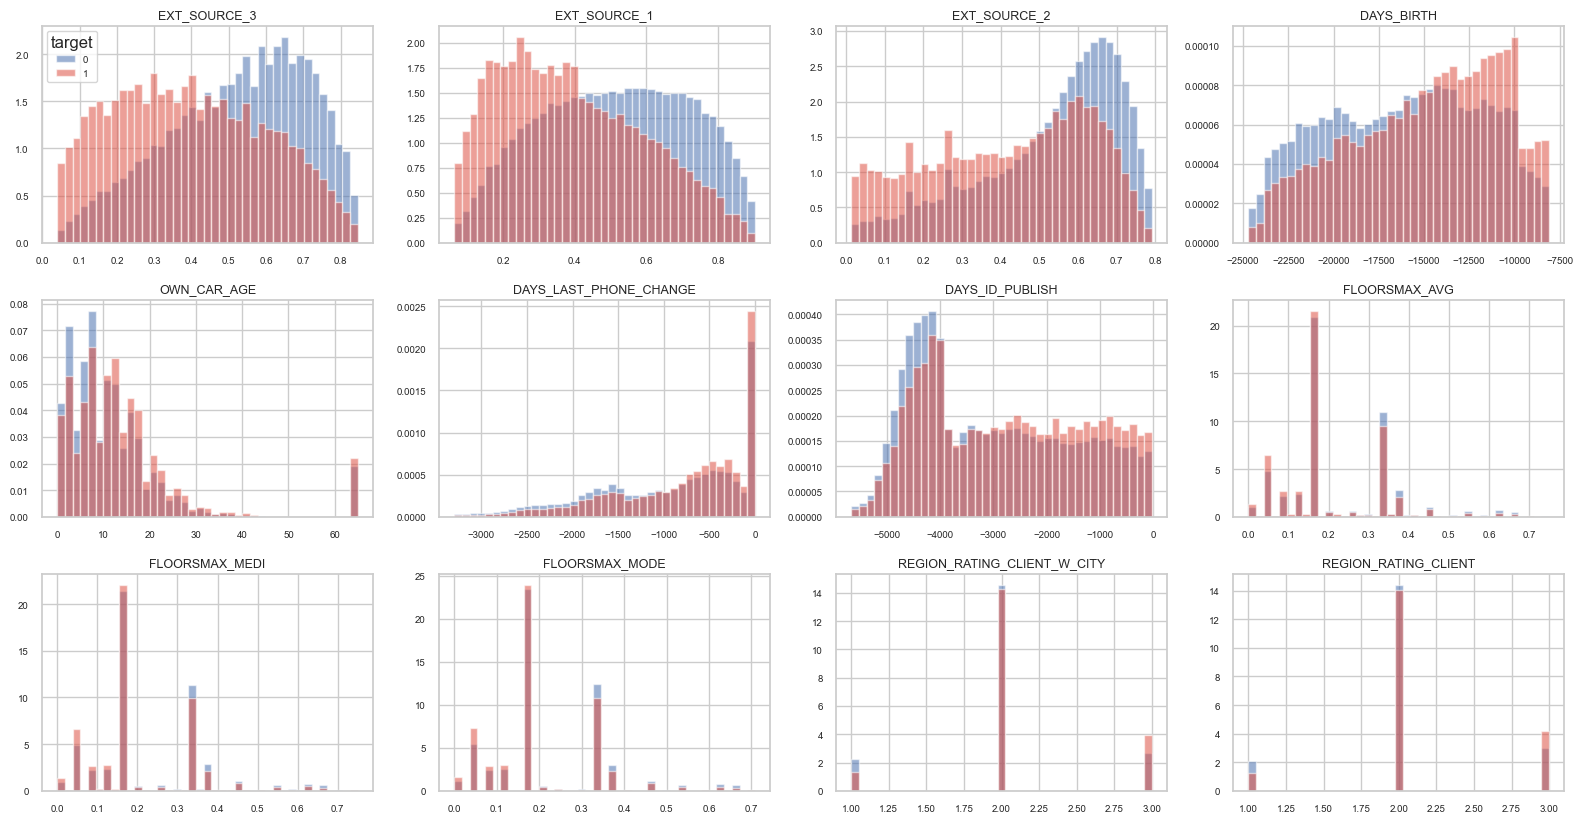

In [7]:
top = prof.sort_values("auc", ascending=False).index[:12].tolist()
plot_df = df.copy()
plot_df["DAYS_EMPLOYED"] = plot_df["DAYS_EMPLOYED"].replace(365243, np.nan)
eda.plot_numeric_by_target(plot_df, top, NAME)

## 7. Biến phân loại: tỉ lệ nợ xấu theo nhóm

Đường nét đứt = bad rate chung.

n  bad_rate  share_pct
feature             level                                                     
NAME_CONTRACT_TYPE  Cash loans                     278232      8.35      90.48
                    Revolving loans                 29279      5.48       9.52
CODE_GENDER         F                              202448       7.0      65.83
                    M                              105059     10.14      34.16
NAME_INCOME_TYPE    Commercial associate            71617      7.48      23.29
                    Pensioner                       55362      5.39       18.0
                    State servant                   21703      5.75       7.06
                    Working                        158774      9.59      51.63
NAME_EDUCATION_TYPE Academic degree                   164      1.83       0.05
                    Higher education                74863      5.36      24.34
                    Incomplete higher               10277      8.48       3.34
                    Lower secondary                  3816     10.93       1.24
                    Secondary / secondary special  218391      8.94      71.02
NAME_FAMILY_STATUS  Civil marriage                  29775      9.94       9.68
                    Married                        196432      7.56      63.88
                    Separated                       19770      8.19       6.43
                    Single / not married            45444      9.81      14.78
                    Widow                           16088      5.82       5.23
OCCUPATION_TYPE     <NA>                            96391      6.51      31.35
                    Accountants                      9813      4.83       3.19
                    Cleaning staff                   4653      9.61       1.51
                    Cooking staff                    5946     10.44       1.93
                    Core staff                      27570       6.3       8.97
                    Drivers                         18603     11.33       6.05
                    HR staff                          563      6.39       0.18
                    High skill tech staff           11380      6.16        3.7
                    IT staff                          526      6.46       0.17
                    Laborers                        55186     10.58      17.95
                    Low-skill Laborers               2093     17.15       0.68
                    Managers                        21371      6.21       6.95
                    Medicine staff                   8537       6.7       2.78
                    Private service staff            2652       6.6       0.86
                    Realty agents                     751      7.86       0.24
                    Sales staff                     32102      9.63      10.44
                    Secretaries                      1305      7.05       0.42
                    Security staff                   6721     10.74       2.19
                    Waiters/barmen staff             1348     11.28       0.44

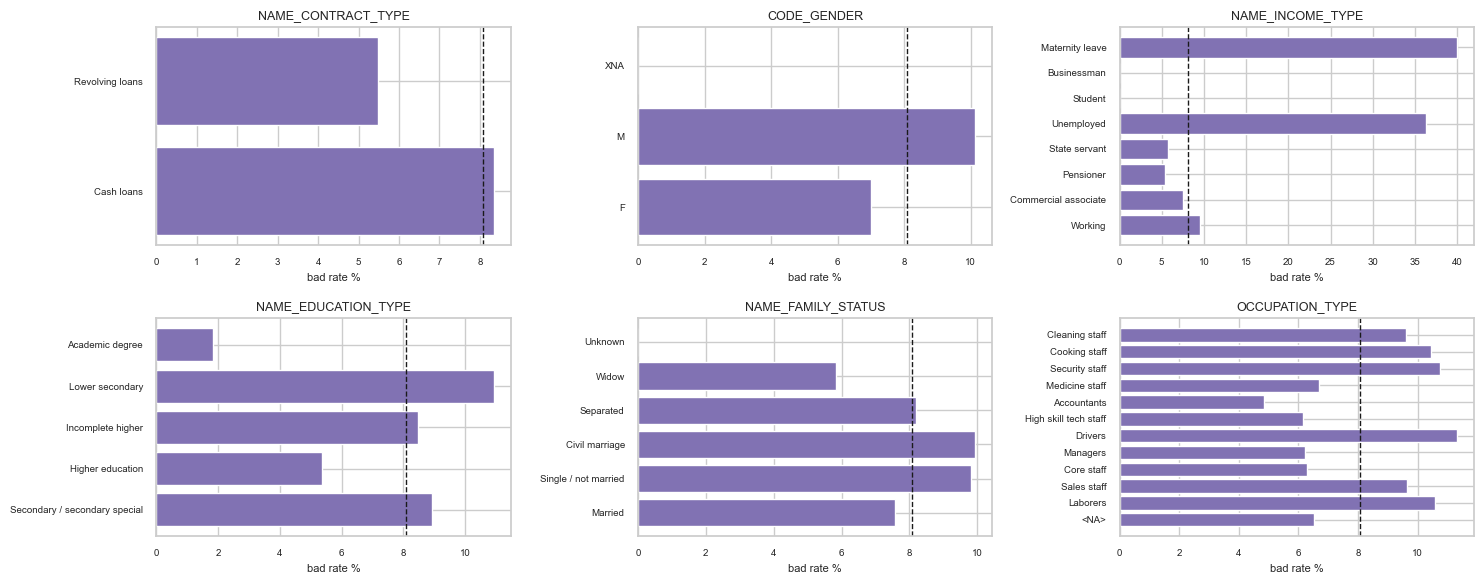

In [8]:
cats = ["NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE",
        "NAME_FAMILY_STATUS", "OCCUPATION_TYPE"]
display(eda.categorical_bad_rate(df, cats).query("n >= 100"))
eda.plot_categorical_bad_rate(df, cats, NAME)

## 8. Tương quan

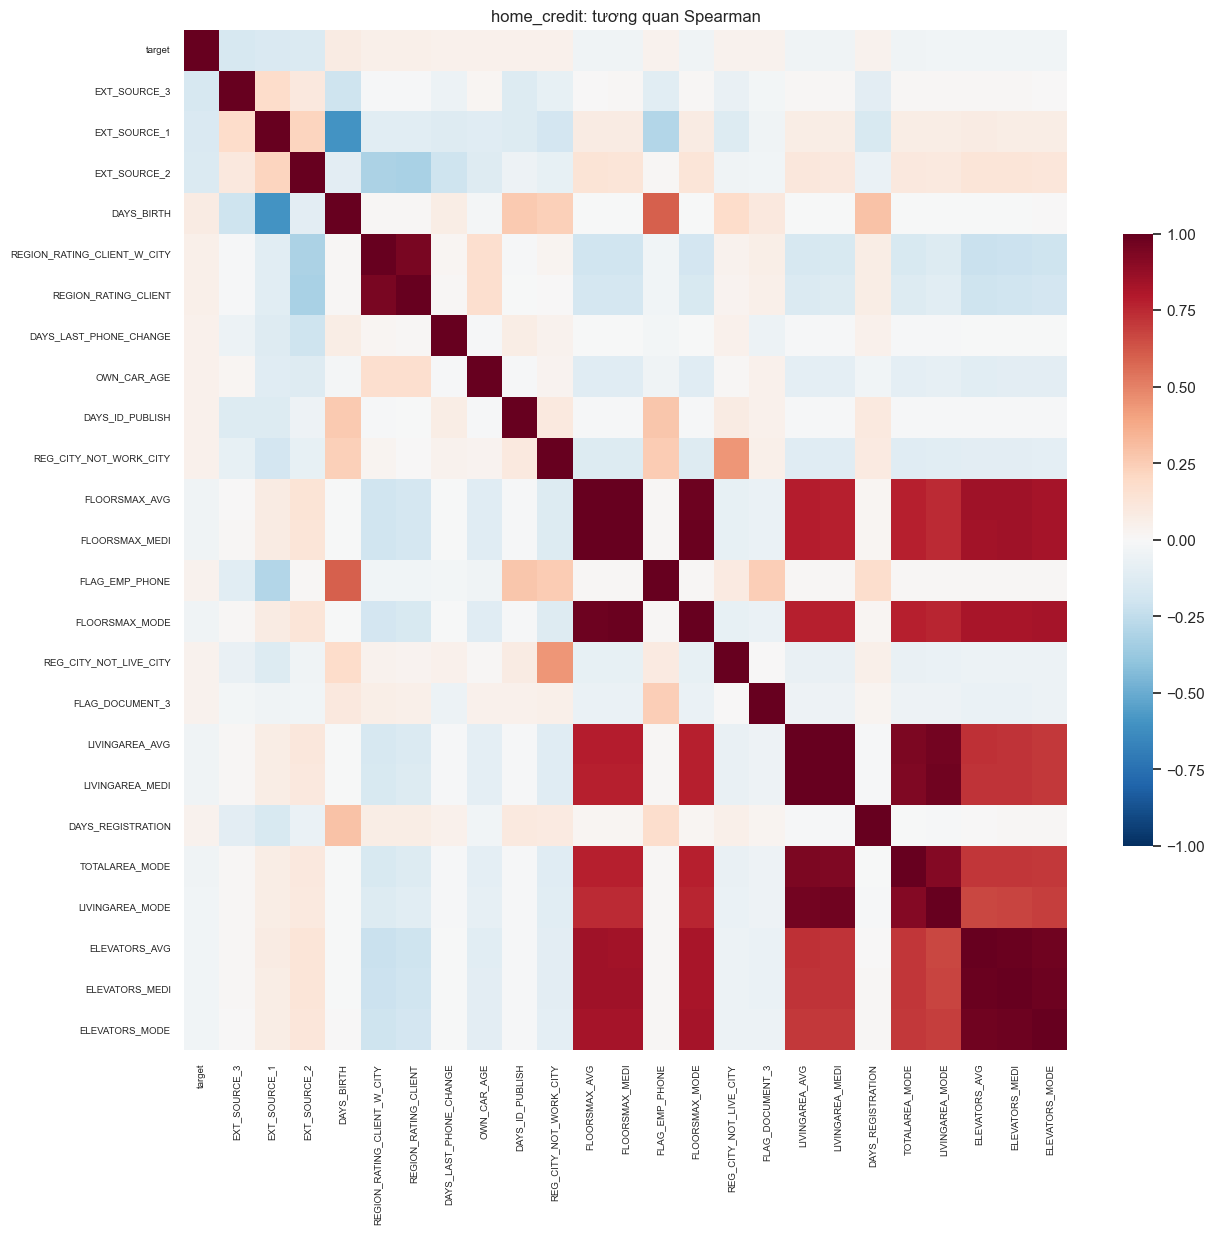

,a,b,spearman
0,LIVINGAREA_AVG,LIVINGAREA_MEDI,0.995506
1,FLOORSMAX_AVG,FLOORSMAX_MEDI,0.994876
2,ELEVATORS_AVG,ELEVATORS_MEDI,0.991028
3,FLOORSMAX_MEDI,FLOORSMAX_MODE,0.986487
4,FLOORSMAX_AVG,FLOORSMAX_MODE,0.981639
5,ELEVATORS_MEDI,ELEVATORS_MODE,0.977774
6,LIVINGAREA_MEDI,LIVINGAREA_MODE,0.969152
7,ELEVATORS_AVG,ELEVATORS_MODE,0.968827
8,LIVINGAREA_AVG,LIVINGAREA_MODE,0.964163
9,REGION_RATING_CLIENT_W_CITY,REGION_RATING_CLIENT,0.950041


In [9]:
corr = eda.correlation_heatmap(df, NAME)
display(eda.high_corr_pairs(corr, thr=0.9).head(20))

## 9. Kiểm tra riêng cho bộ dữ liệu

### Bảng phụ

In [10]:
import pyarrow.parquet as pq
rows = []
for p in sorted(HC.glob("*.parquet")):
    meta = pq.ParquetFile(p).metadata
    rows.append({"table": p.stem, "rows": meta.num_rows, "cols": meta.num_columns})
display(pd.DataFrame(rows))
b = pd.read_parquet(HC / "bureau.parquet", columns=["SK_ID_CURR"])
pa_ = pd.read_parquet(HC / "previous_application.parquet", columns=["SK_ID_CURR"])
print(f"Khách có bản ghi bureau: {df.SK_ID_CURR.isin(b.SK_ID_CURR).mean():.1%}; "
      f"có hồ sơ vay trước tại Home Credit: {df.SK_ID_CURR.isin(pa_.SK_ID_CURR).mean():.1%}")

,table,rows,cols
0,POS_CASH_balance,10001358,8
1,application_test,48744,121
2,application_train,307511,122
3,bureau,1716428,17
4,bureau_balance,27299925,3
5,credit_card_balance,3840312,23
6,installments_payments,13605401,8
7,previous_application,1670214,37


Khách có bản ghi bureau: 85.7%; có hồ sơ vay trước tại Home Credit: 94.6%


### Giá trị bất thường

In [11]:
anom = df["DAYS_EMPLOYED"] == 365243
print(f"DAYS_EMPLOYED = 365243 (≈1000 năm, mã cho người không đi làm/hưu trí): {anom.sum():,} dòng ({anom.mean():.1%}), "
      f"bad rate {df.loc[anom, 'target'].mean():.1%} vs {df.loc[~anom, 'target'].mean():.1%}")
print("AMT_INCOME_TOTAL max:", f"{df.AMT_INCOME_TOTAL.max():,.0f}", "— median:", f"{df.AMT_INCOME_TOTAL.median():,.0f}")
print("CODE_GENDER:", df.CODE_GENDER.value_counts().to_dict())
print("ORGANIZATION_TYPE = 'XNA':", (df.ORGANIZATION_TYPE == "XNA").sum())
m = df.isna().mean()
print(f"Cột thiếu > 50%: {(m > 0.5).sum()} / {df.shape[1]} (chủ yếu nhóm đặc trưng căn hộ *_AVG/_MODE/_MEDI)")
flags = [c for c in df if c.startswith("FLAG_DOCUMENT")]
print(f"FLAG_DOCUMENT_* gần như hằng (<1% = 1): {sum(df[c].mean() < 0.01 for c in flags)} / {len(flags)}")
age = -df.DAYS_BIRTH / 365.25
display(df.groupby(pd.cut(age, [20, 30, 40, 50, 60, 70]), observed=True)["target"].agg(["size", "mean"]).rename_axis("tuổi"))

DAYS_EMPLOYED = 365243 (≈1000 năm, mã cho người không đi làm/hưu trí): 55,374 dòng (18.0%), bad rate 5.4% vs 8.7%
AMT_INCOME_TOTAL max: 117,000,000 — median: 147,150
CODE_GENDER: {'F': 202448, 'M': 105059, 'XNA': 4}
ORGANIZATION_TYPE = 'XNA': 55374
Cột thiếu > 50%: 41 / 122 (chủ yếu nhóm đặc trưng căn hộ *_AVG/_MODE/_MEDI)
FLAG_DOCUMENT_* gần như hằng (<1% = 1): 16 / 20


,size,mean
tuổi,,
"(20, 30]",45186,0.114438
"(30, 40]",82349,0.095897
"(40, 50]",76581,0.076429
"(50, 60]",68109,0.061196
"(60, 70]",35286,0.049198


## 10. Nhận xét

- **Nhãn: mất cân bằng nặng** — bad rate ≈ **8,1%** (≈ 11:1), tương tự GMSC. Nhãn định nghĩa là “trễ hạn hơn X ngày trong Y kỳ đầu tiên” → nhãn *sớm* (early default), không phải vỡ nợ cuối cùng.
- **Dữ liệu rộng và thưa:** 121 đặc trưng, ~24% ô bị thiếu, **41 cột thiếu > 50%** (thông tin về nhà ở). Thiếu dữ liệu mang thông tin yếu (chênh bad rate chỉ vài điểm %).
- **Tín hiệu yếu và phân tán:** không biến đơn nào có AUC > 0,68; ba điểm tín dụng bên ngoài `EXT_SOURCE_1/2/3` là mạnh nhất, tiếp theo là tuổi (người trẻ bad rate ~11,5% so với ~5% ở nhóm 60+). Cần kết hợp nhiều đặc trưng và khai thác các bảng phụ.
- **Giá trị bất thường:** `DAYS_EMPLOYED = 365243` ở ~18% hồ sơ (mã cho người không đi làm; bad rate thấp hơn, ~5,4%); thu nhập max 117 triệu (skew ≈ 390); `CODE_GENDER = XNA`.
- 22/73 biến số có |skew| > 5; nhiều cặp biến trùng lặp gần như hoàn toàn (nhóm *_AVG/_MODE/_MEDI), 16/20 cờ tài liệu gần như hằng.
- **Cấu trúc quan hệ:** dữ liệu gồm 7 bảng (tới 27 triệu dòng) → cần tổng hợp (aggregation) theo khách hàng trước khi mô hình hoá — khác hẳn các bộ dữ liệu một bảng còn lại.

In [12]:
EXTRA = {"days_employed_anomaly_pct": round(100 * anom.mean(), 2), "cols_missing_gt50": int((m > 0.5).sum())}
eda.save_summary(NAME, {
    "name": NAME,
    "overview": ov.to_dict(),
    "target": tgt,
    "missing_top": miss["missing_pct"].head(10).to_dict() if len(miss) else {},
    "n_numeric_abs_skew_gt2": int((prof["skew"].abs() > 2).sum()),
    "n_numeric": int(len(prof)),
    "max_abs_skew": float(prof["skew"].abs().max()),
    "top_auc": prof["auc"].sort_values(ascending=False).head(5).to_dict(),
    **EXTRA,
})